# Panel flutter analysis

This example finds the flutter onset of flat panels in a supersonic flow, with and without an in-plane pre-stress, by tracing their natural frequencies as the aerodynamic pressure grows, and compares it with the literature: an isotropic square plate, the same plate under a biaxial compression, and a cross-ply laminated plate, all simply supported, against the values of Singha and Ganapathi (2005) and of the references they list.

The aerodynamic load of the linear piston theory is proportional to the slope of the panel along the flow, $q = \beta w_{,x} + \gamma w$ for a flow along $x$. The aerodynamic pressure parameter is $\beta$, and $\gamma$ is the curvature correction of Krumhaar (1963), which softens a cylindrical shell; $\gamma = 0$ for the flat plates of this example. The load gives the aerodynamic stiffness matrix, `Shell.calc_kA`, a function of the attribute `beta` of the `Shell` object:

$$
\boldsymbol{K}_A = -\int \left(\beta (\boldsymbol{S}^w_{,x})^\top \boldsymbol{S}^w + \gamma (\boldsymbol{S}^w)^\top \boldsymbol{S}^w\right) dA,
$$

with the row $\boldsymbol{S}^w$ of the approximation functions of $w$. $\boldsymbol{K}_A$ is not symmetric. The natural frequencies follow from

$$
(\boldsymbol{K}_C + \boldsymbol{K}_G + \boldsymbol{K}_A + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}, \qquad \lambda^2 = -\omega^2,
$$

solved with `structsolve.freq`. As $\beta$ increases, two natural frequencies approach each other and coalesce. Beyond that point the eigenvalues are complex conjugates, and the panel flutters. The flutter onset is the lowest $\beta$ with a complex frequency.

The term in $\beta$ is the transpose of that of Eq. (21) of Castro et al. (2016). For $w = 0$ at the leading and trailing edges, this corresponds to reversing the flow direction and does not change the flutter boundary. The sign of the term in $\gamma$ of Eqs. (21) and (29) of that paper is reversed, a mistake of the paper. The aerodynamic damping, `Shell.calc_cA`, is $i \boldsymbol{C}_A$ with $\boldsymbol{C}_A$ of Eq. (23) of the paper, entering the eigenvalue problem as $+\omega \boldsymbol{C}_A$; it is not used here. See also [Aeroelasticity](../aeroelasticity.rst).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import freq
from panels.shell import Shell

MODELS = ['plate_clpt_donnell', 'cylshell_clpt_donnell',
          'cylshell_clpt_sanders', 'plate_fsdt_donnell', 'plate_tsdt_donnell']


def results_table(rows):
    # Markdown table of (quantity, panels, reference, source) rows
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## The aerodynamic pressure parameter in the literature and in panels

Singha and Ganapathi (2005, Eq. (10), p. 57) use the first-order high Mach number approximation of the linear potential flow theory, the linear piston theory, with the aerodynamic pressure $\lambda\, \partial u_3/\partial x_1$, where

$$
\lambda = \frac{\rho_a U_a^2}{\sqrt{M^2 - 1}},
$$

with the air density $\rho_a$, the flow speed $U_a$ and the Mach number $M$, plus an aerodynamic damping term in $\partial u_3/\partial t$, which they neglect when the flutter onset is found from the coalescence of two frequencies (Singha and Ganapathi, 2005, p. 57), as here. In `panels`, when `beta` is not given, `Shell.calc_kA` computes it from the attributes `rho_air`, `air_speed` and `Mach` as $\beta = \rho_{air} U^2/\sqrt{M^2 - 1}$ (see the docstring of `Shell.calc_kA`): $\beta$ is the parameter $\lambda$ of Singha and Ganapathi, in N/m³. Their results are given with the non-dimensional parameters

$$
\bar{\lambda} = \frac{\beta a^3}{D} \quad \text{(isotropic plates)}, \qquad
\bar{\lambda} = \frac{\beta a^3}{E_T h^3} \quad \text{(laminates)},
$$

where $D = E h^3/(12(1 - \nu^2))$ and $E_T$ is the transverse modulus of the ply. The first is also the parameter $\lambda = 2 q a^3/(\sqrt{M^2 - 1} D)$ used by Dowell (1970, p. 385), with the dynamic pressure $q = \rho_a U_a^2/2$. The cell below checks the conversion with `Shell.calc_kA`, for a flow at $M = 2$:

In [2]:
E, nu = 70e9, 0.3
a = 1.
h = a/100
D = E*h**3/(12*(1 - nu**2))
s = Shell(model='plate_clpt_donnell', a=a, b=a, stack=[0.], plyt=h,
          laminaprop=(E, nu), rho=2700., m=4, n=4)
s.flow = 'x'
s.Mach = 2.
s.rho_air = 0.4  # kg/m^3
s.air_speed = 590.  # m/s
s.beta = None
s.calc_kA()
print('beta from calc_kA:             %.6g N/m^3' % s.beta)
print('rho_air U^2/sqrt(M^2 - 1):     %.6g N/m^3'
      % (s.rho_air*s.air_speed**2/np.sqrt(s.Mach**2 - 1)))
print('2 q a^3/(sqrt(M^2 - 1) D):     %.6g'
      % (2*(0.5*s.rho_air*s.air_speed**2)*a**3/(np.sqrt(s.Mach**2 - 1)*D)))
print('lambda bar = beta a^3/D:       %.6g' % (s.beta*a**3/D))

beta from calc_kA:             80390.3 N/m^3
rho_air U^2/sqrt(M^2 - 1):     80390.3 N/m^3
2 q a^3/(sqrt(M^2 - 1) D):     12.5409
lambda bar = beta a^3/D:       12.5409


## Finding the flutter onset

For a given $\beta$, the eigenvalues $\lambda^2$ are all real before the onset and some are complex after it. $\boldsymbol{K}_C$, $\boldsymbol{K}_G$ and $\boldsymbol{M}$ do not depend on $\beta$ and are computed once; the onset is found by bisection between a $\beta$ without and a $\beta$ with complex eigenvalues, to a relative tolerance of $10^{-5}$. An eigenvalue is taken as complex when its imaginary part is larger than $10^{-8}$ times its modulus.

In [3]:
def has_complex_frequency(shell, K, kM, beta):
    shell.beta = beta
    eigvals, _ = freq(K + shell.calc_kA(), kM, sparse_solver=True,
                      silent=True)
    return np.any(np.abs(eigvals.imag) > 1e-8*np.abs(eigvals))


def flutter_onset(shell, beta_low, beta_high, rtol=1e-5):
    K = shell.calc_kC()
    if shell.Nxx or shell.Nyy:
        K = K + shell.calc_kG()
    kM = shell.calc_kM()
    if (has_complex_frequency(shell, K, kM, beta_low)
            or not has_complex_frequency(shell, K, kM, beta_high)):
        raise ValueError('the onset is not between beta_low and beta_high')
    while beta_high - beta_low > rtol*beta_high:
        beta = 0.5*(beta_low + beta_high)
        if has_complex_frequency(shell, K, kM, beta):
            beta_high = beta
        else:
            beta_low = beta
    return 0.5*(beta_low + beta_high)

## Isotropic square plate

Singha and Ganapathi (2005, Table 2, p. 59) give for the simply supported isotropic square plate, $a/h = 100$, the critical parameter $\bar{\lambda}_{cr}/\pi^4 = 5.27$ with their finite element, and list 5.12 from Liao and Sun (1993) and 5.25 from Chowdary et al. (1996). The plate has $E = 70$ GPa and $\nu = 0.3$; with the classical plate theory $\bar{\lambda}_{cr}$ depends neither on $E$ nor on $h$.

In [4]:
# Singha and Ganapathi (2005), Table 2, skew angle 0, simply supported
REF_ISO = [(5.27*np.pi**4, 'Singha and Ganapathi (2005), Table 2'),
           (5.12*np.pi**4, 'Liao and Sun (1993), in Singha and Ganapathi (2005), Table 2'),
           (5.25*np.pi**4, 'Chowdary et al. (1996), in Singha and Ganapathi (2005), Table 2')]


def isotropic_plate(model, a_h, Nxx=0., Nyy=0.):
    s = Shell(model=model, a=a, b=a, r=1.e8, stack=[0.], plyt=a/a_h,
              laminaprop=(E, nu), rho=2700., m=12, n=12)
    s.Nxx, s.Nyy = Nxx, Nyy
    D = E*s.plyt**3/(12*(1 - nu**2))
    return s, D


rows = []
for model in MODELS:
    s, D = isotropic_plate(model, 100.)
    beta_cr = flutter_onset(s, 1.*D/a**3, 1000.*D/a**3)
    lambda_cr = beta_cr*a**3/D
    print('%-22s beta_cr = %.6g N/m^3, lambda_cr = %.3f = %.4f pi^4'
          % (model, beta_cr, lambda_cr, lambda_cr/np.pi**4))
    refs = REF_ISO if model == 'plate_clpt_donnell' else REF_ISO[:1]
    for ref, src in refs:
        rows.append(('`%s`, $\\bar{\\lambda}_{cr}$' % model, lambda_cr, ref,
                     src))
results_table(rows)

plate_clpt_donnell     beta_cr = 3.28534e+06 N/m^3, lambda_cr = 512.514 = 5.2615 pi^4


cylshell_clpt_donnell  beta_cr = 3.28534e+06 N/m^3, lambda_cr = 512.514 = 5.2615 pi^4


cylshell_clpt_sanders  beta_cr = 3.28534e+06 N/m^3, lambda_cr = 512.514 = 5.2615 pi^4


plate_fsdt_donnell     beta_cr = 3.28232e+06 N/m^3, lambda_cr = 512.041 = 5.2566 pi^4


plate_tsdt_donnell     beta_cr = 3.28232e+06 N/m^3, lambda_cr = 512.041 = 5.2566 pi^4


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, $\bar{\lambda}_{cr}$ | 512.514 | 513.346 | -1.62e-03 | Singha and Ganapathi (2005), Table 2 |
| `plate_clpt_donnell`, $\bar{\lambda}_{cr}$ | 512.514 | 498.735 | +2.76e-02 | Liao and Sun (1993), in Singha and Ganapathi (2005), Table 2 |
| `plate_clpt_donnell`, $\bar{\lambda}_{cr}$ | 512.514 | 511.398 | +2.18e-03 | Chowdary et al. (1996), in Singha and Ganapathi (2005), Table 2 |
| `cylshell_clpt_donnell`, $\bar{\lambda}_{cr}$ | 512.514 | 513.346 | -1.62e-03 | Singha and Ganapathi (2005), Table 2 |
| `cylshell_clpt_sanders`, $\bar{\lambda}_{cr}$ | 512.514 | 513.346 | -1.62e-03 | Singha and Ganapathi (2005), Table 2 |
| `plate_fsdt_donnell`, $\bar{\lambda}_{cr}$ | 512.041 | 513.346 | -2.54e-03 | Singha and Ganapathi (2005), Table 2 |
| `plate_tsdt_donnell`, $\bar{\lambda}_{cr}$ | 512.041 | 513.346 | -2.54e-03 | Singha and Ganapathi (2005), Table 2 |

The models give $\bar{\lambda}_{cr}/\pi^4 \approx 5.26$, between the values of the three references, which differ among themselves by 3%. For the isotropic plate the flutter mode is, in general, the coalescence of the first two modes (Liao and Sun, 1993, p. 1901; Singha and Ganapathi, 2005, p. 60). The FSDT and TSDT models give an onset 0.1% lower than the CLPT models, the effect of the transverse shear at $a/h = 100$.

## Isotropic square plate with pre-stress

Singha and Ganapathi (2005, Table 3, p. 59) give the flutter boundary of the simply supported isotropic square plate, $a/h = 240$, $\nu = 0.3$, under a thermal stress $T/T_{cr} = 0.8$ and under a biaxial compressive stress $P/P_{cr} = 1.0$, with values of other authors. For a plate whose edges are restrained in the plane, a uniform temperature rise $T$ gives a uniform biaxial compression proportional to $T$, $N_{xx} = N_{yy} = -E\alpha h T/(1 - \nu)$, so both cases are the pre-stress $N_{xx} = N_{yy} = -P$, with $P/P_{cr} = 0.8$ and $1.0$. The buckling load under equal biaxial compression follows from Eq. (10.44) of Leissa (1969, p. 277) with $\omega = 0$ and $m = n = 1$:

$$
P_{cr} = \frac{2\pi^2 D}{a^2}.
$$

At $P = P_{cr}$ the first frequency is zero without flow; the flow still couples it with the second mode, and the coalescence, at a lower $\bar{\lambda}$ than without pre-stress, gives the onset.

In [5]:
# Singha and Ganapathi (2005), Table 3
REF_PRE = {0.8: [(376.271, 'Singha and Ganapathi (2005), Table 3'),
                 (376.125, 'Ganapathi and Touratier (1996), in Singha and Ganapathi (2005), Table 3'),
                 (371.093, 'Xue and Mei (1993), in Singha and Ganapathi (2005), Table 3')],
           1.0: [(343.15, 'Singha and Ganapathi (2005), Table 3'),
                 (342.0, 'Han and Yang (1983), in Singha and Ganapathi (2005), Table 3'),
                 (343.45, 'Ganapathi (1992), in Singha and Ganapathi (2005), Table 3')]}
rows = []
for model in MODELS:
    for ratio in (0.8, 1.0):
        s, D = isotropic_plate(model, 240.)
        Pcr = 2*np.pi**2*D/a**2
        s.Nxx = s.Nyy = -ratio*Pcr
        beta_cr = flutter_onset(s, 1.*D/a**3, 1000.*D/a**3)
        lambda_cr = beta_cr*a**3/D
        print('%-22s P/Pcr = %.1f: lambda_cr = %.3f' % (model, ratio, lambda_cr))
        refs = REF_PRE[ratio] if model == 'plate_clpt_donnell' else REF_PRE[ratio][:1]
        for ref, src in refs:
            rows.append(('`%s`, $P/P_{cr} = %.1f$, $\\bar{\\lambda}_{cr}$'
                         % (model, ratio), lambda_cr, ref, src))
results_table(rows)

plate_clpt_donnell     P/Pcr = 0.8: lambda_cr = 375.916


plate_clpt_donnell     P/Pcr = 1.0: lambda_cr = 343.346


cylshell_clpt_donnell  P/Pcr = 0.8: lambda_cr = 375.916


cylshell_clpt_donnell  P/Pcr = 1.0: lambda_cr = 343.346


cylshell_clpt_sanders  P/Pcr = 0.8: lambda_cr = 375.916


cylshell_clpt_sanders  P/Pcr = 1.0: lambda_cr = 343.346


plate_fsdt_donnell     P/Pcr = 0.8: lambda_cr = 375.815


plate_fsdt_donnell     P/Pcr = 1.0: lambda_cr = 343.241


plate_tsdt_donnell     P/Pcr = 0.8: lambda_cr = 375.815


plate_tsdt_donnell     P/Pcr = 1.0: lambda_cr = 343.241


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, $P/P_{cr} = 0.8$, $\bar{\lambda}_{cr}$ | 375.916 | 376.271 | -9.45e-04 | Singha and Ganapathi (2005), Table 3 |
| `plate_clpt_donnell`, $P/P_{cr} = 0.8$, $\bar{\lambda}_{cr}$ | 375.916 | 376.125 | -5.57e-04 | Ganapathi and Touratier (1996), in Singha and Ganapathi (2005), Table 3 |
| `plate_clpt_donnell`, $P/P_{cr} = 0.8$, $\bar{\lambda}_{cr}$ | 375.916 | 371.093 | +1.30e-02 | Xue and Mei (1993), in Singha and Ganapathi (2005), Table 3 |
| `plate_clpt_donnell`, $P/P_{cr} = 1.0$, $\bar{\lambda}_{cr}$ | 343.346 | 343.15 | +5.71e-04 | Singha and Ganapathi (2005), Table 3 |
| `plate_clpt_donnell`, $P/P_{cr} = 1.0$, $\bar{\lambda}_{cr}$ | 343.346 | 342 | +3.94e-03 | Han and Yang (1983), in Singha and Ganapathi (2005), Table 3 |
| `plate_clpt_donnell`, $P/P_{cr} = 1.0$, $\bar{\lambda}_{cr}$ | 343.346 | 343.45 | -3.03e-04 | Ganapathi (1992), in Singha and Ganapathi (2005), Table 3 |
| `cylshell_clpt_donnell`, $P/P_{cr} = 0.8$, $\bar{\lambda}_{cr}$ | 375.916 | 376.271 | -9.45e-04 | Singha and Ganapathi (2005), Table 3 |
| `cylshell_clpt_donnell`, $P/P_{cr} = 1.0$, $\bar{\lambda}_{cr}$ | 343.346 | 343.15 | +5.71e-04 | Singha and Ganapathi (2005), Table 3 |
| `cylshell_clpt_sanders`, $P/P_{cr} = 0.8$, $\bar{\lambda}_{cr}$ | 375.916 | 376.271 | -9.45e-04 | Singha and Ganapathi (2005), Table 3 |
| `cylshell_clpt_sanders`, $P/P_{cr} = 1.0$, $\bar{\lambda}_{cr}$ | 343.346 | 343.15 | +5.71e-04 | Singha and Ganapathi (2005), Table 3 |
| `plate_fsdt_donnell`, $P/P_{cr} = 0.8$, $\bar{\lambda}_{cr}$ | 375.815 | 376.271 | -1.21e-03 | Singha and Ganapathi (2005), Table 3 |
| `plate_fsdt_donnell`, $P/P_{cr} = 1.0$, $\bar{\lambda}_{cr}$ | 343.241 | 343.15 | +2.65e-04 | Singha and Ganapathi (2005), Table 3 |
| `plate_tsdt_donnell`, $P/P_{cr} = 0.8$, $\bar{\lambda}_{cr}$ | 375.815 | 376.271 | -1.21e-03 | Singha and Ganapathi (2005), Table 3 |
| `plate_tsdt_donnell`, $P/P_{cr} = 1.0$, $\bar{\lambda}_{cr}$ | 343.241 | 343.15 | +2.65e-04 | Singha and Ganapathi (2005), Table 3 |

The compression lowers the flutter onset from $\bar{\lambda}_{cr} \approx 513$ to about 376 and 343, and the models agree with the finite element results of Singha and Ganapathi (2005), Ganapathi and Touratier (1996), Han and Yang (1983) and Ganapathi (1992) within 0.4%. The value of Xue and Mei (1993) is about 1.3% lower than those of `panels` and of the other references.

## Cross-ply laminated plate: frequency coalescence

Singha and Ganapathi (2005, Fig. 2a and p. 60) study the simply supported square plate with the cross-ply laminate $[0/90/0/90/0]$ of plies of equal thickness, $a/h = 100$, with the ply properties $E_L/E_T = 40$, $G_{LT}/E_T = 0.6$, $G_{TT}/E_T = 0.5$, $\nu_{LT} = 0.25$ (p. 58), the fibres of the $0°$ plies along the flow. They plot the non-dimensional frequencies $\bar{\omega} = \omega a^2 \sqrt{\rho/E_T}/(\pi^2 h)$ against $\bar{\lambda} = \beta a^3/(E_T h^3)$ and find the first coalescence, of the first and third modes, at $\bar{\lambda}_{cr} = 909.53$ (p. 60). As in the paper, $E_T = 1$ and $\rho = 1$ are used.

In [6]:
ET = 1.
lam_singha = (40*ET, ET, 0.25, 0.6*ET, 0.6*ET, 0.5*ET)
h_l = a/100


def crossply_plate(model):
    return Shell(model=model, a=a, b=a, r=1.e8, stack=[0, 90, 0, 90, 0],
                 plyt=h_l/5, laminaprop=lam_singha, rho=1., m=12, n=12)


s = crossply_plate('plate_clpt_donnell')
kC = s.calc_kC()
kM = s.calc_kM()
lambdas = np.linspace(0., 1200., 121)
omegas = []
for lambda_bar in lambdas:
    s.beta = lambda_bar*ET*h_l**3/a**3
    eigvals, _ = freq(kC + s.calc_kA(), kM, sparse_solver=True, silent=True)
    omegas.append(np.sqrt(-eigvals[:6])*a**2/(np.pi**2*h_l)*np.sqrt(s.rho/ET))
omegas = np.array(omegas)
print('in vacuo, lambda = 0: omega bar =', np.round(omegas[0].real, 4))
# the same frequencies from the closed form of the specially orthotropic
# plate, Leissa (1969), Eq. (10.1), with m half-waves along the flow
Dm = s.lam.D
for m, n in ((1, 1), (1, 2), (2, 1), (2, 2), (1, 3), (2, 3)):
    w2 = np.pi**4*(Dm[0, 0]*(m/a)**4 + 2*(Dm[0, 1] + 2*Dm[2, 2])*(m/a)**2*(n/a)**2
                   + Dm[1, 1]*(n/a)**4)/(s.rho*h_l)
    print('(m, n) = (%d, %d): omega bar = %.4f'
          % (m, n, np.sqrt(w2)*a**2/(np.pi**2*h_l)*np.sqrt(s.rho/ET)))

in vacuo, lambda = 0: omega bar = [ 1.9139  3.9737  6.6553  7.6538  8.1477 10.6192]
(m, n) = (1, 1): omega bar = 1.9141
(m, n) = (1, 2): omega bar = 3.9745
(m, n) = (2, 1): omega bar = 6.6567
(m, n) = (2, 2): omega bar = 7.6564
(m, n) = (1, 3): omega bar = 8.1510
(m, n) = (2, 3): omega bar = 10.6249


The laminate is specially orthotropic, $D_{16} = D_{26} = 0$, and the in vacuo modes are $w = \sin(m\pi x/a)\sin(n\pi y/b)$: in order, $(m, n) = (1, 1), (1, 2), (2, 1), (2, 2), (1, 3), (2, 3)$, as the closed form printed above shows. With $\int_0^a \sin(m\pi x/a)\, \partial \sin(m'\pi x/a)/\partial x\, dx = 0$ for $m + m'$ even, and the orthogonality along $y$, the aerodynamic load couples only modes with the same $n$ and $m + m'$ odd: the first mode, $(1, 1)$, with the third, $(2, 1)$, and the second, $(1, 2)$, with the fourth, $(2, 2)$.

The plot shows the real parts of the six lowest non-dimensional frequencies against $\bar{\lambda}$, sorted by value, so that a curve passes from one mode to another where two modes cross. The first frequency rises and the frequency of the mode $(2, 1)$ falls, crossing the rising frequency of the mode $(1, 2)$, until they coalesce at the onset, the dashed line: the first and third modes, as found by Singha and Ganapathi (2005, p. 60). The modes $(1, 2)$ and $(2, 2)$ coalesce at a higher $\bar{\lambda}$, as the second and fourth modes of the paper, at 964.78.

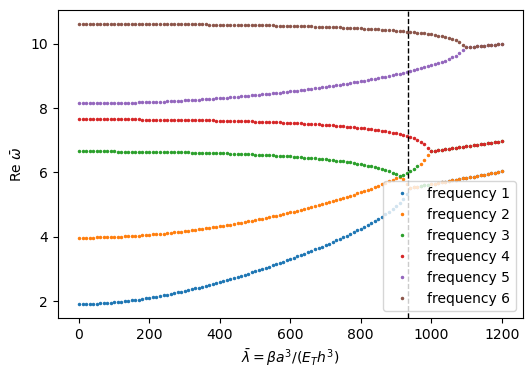

In [7]:
beta_cr = flutter_onset(crossply_plate('plate_clpt_donnell'),
                        100.*ET*h_l**3/a**3, 1500.*ET*h_l**3/a**3)
lambda_cr_clpt = beta_cr*a**3/(ET*h_l**3)
fig, ax = plt.subplots(figsize=(6, 4))
for j in range(6):
    ax.plot(lambdas, omegas[:, j].real, '.', ms=3,
            label='frequency %d' % (j + 1))
ax.axvline(lambda_cr_clpt, ls='--', color='k', lw=1)
ax.set_xlabel(r'$\bar{\lambda} = \beta a^3/(E_T h^3)$')
ax.set_ylabel(r'Re $\bar{\omega}$')
ax.legend()
plt.show()

The onset for the five models:

In [8]:
rows = []
for model in MODELS:
    beta_cr = flutter_onset(crossply_plate(model), 100.*ET*h_l**3/a**3,
                            1500.*ET*h_l**3/a**3)
    lambda_cr = beta_cr*a**3/(ET*h_l**3)
    print('%-22s lambda_cr = %.3f' % (model, lambda_cr))
    rows.append(('`%s`, $\\bar{\\lambda}_{cr}$' % model, lambda_cr, 909.53,
                 'Singha and Ganapathi (2005), p. 60'))
results_table(rows)

plate_clpt_donnell     lambda_cr = 933.165


cylshell_clpt_donnell  lambda_cr = 933.165


cylshell_clpt_sanders  lambda_cr = 933.165


plate_fsdt_donnell     lambda_cr = 920.497


plate_tsdt_donnell     lambda_cr = 920.860


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, $\bar{\lambda}_{cr}$ | 933.165 | 909.53 | +2.60e-02 | Singha and Ganapathi (2005), p. 60 |
| `cylshell_clpt_donnell`, $\bar{\lambda}_{cr}$ | 933.165 | 909.53 | +2.60e-02 | Singha and Ganapathi (2005), p. 60 |
| `cylshell_clpt_sanders`, $\bar{\lambda}_{cr}$ | 933.165 | 909.53 | +2.60e-02 | Singha and Ganapathi (2005), p. 60 |
| `plate_fsdt_donnell`, $\bar{\lambda}_{cr}$ | 920.497 | 909.53 | +1.21e-02 | Singha and Ganapathi (2005), p. 60 |
| `plate_tsdt_donnell`, $\bar{\lambda}_{cr}$ | 920.86 | 909.53 | +1.25e-02 | Singha and Ganapathi (2005), p. 60 |

The CLPT models give a flutter onset about 2.6% higher than Singha and Ganapathi (2005), and the FSDT and TSDT models about 1.2% higher. The transverse shear matters more for this laminate than for the isotropic plate, since $E_L/G_{LT} = 67$, and it lowers the onset, which explains part of the difference with the CLPT models; the shear deformation models also differ in the kinematics and the shear correction from the finite element of the paper, which includes the transverse shear strains as independent fields interpolated linearly, on an $8 \times 8$ mesh (Singha and Ganapathi, 2005, pp. 57-58). The Ritz solution of `panels` is converged in the number of terms. The coalescing modes, the first and third, are those of the paper.

## References

1. S. G. P. Castro, T. A. M. Guimarães, D. A. Rade and M. V. Donadon, "Flutter of stiffened composite panels considering the stiffener's base as a structural element". Composite Structures, 140:36-43, 2016. https://doi.org/10.1016/j.compstruct.2015.12.056.
2. T. V. R. Chowdary, P. K. Sinha and S. Parthan, "Finite element flutter analysis of composite skew panels". Computers & Structures, 58(3):613-620, 1996. https://doi.org/10.1016/0045-7949(95)00153-8.
3. E. H. Dowell, "Panel flutter: a review of the aeroelastic stability of plates and shells". AIAA Journal, 8(3):385-399, 1970. https://doi.org/10.2514/3.5680.
4. M. Ganapathi, "Dynamic analysis of laminated composite shell using field-consistent finite elements". PhD dissertation, Department of Aerospace Engineering, IIT Madras, 1992 (as cited by Singha and Ganapathi, 2005).
5. M. Ganapathi and M. Touratier, "Supersonic flutter analysis of thermally stressed laminated composite flat panels". Composite Structures, 34(2):241-248, 1996. https://doi.org/10.1016/0263-8223(95)00148-4.
6. A. D. Han and T. Y. Yang, "Nonlinear panel flutter using high-order triangular finite elements". AIAA Journal, 21(10):1453-1461, 1983. https://doi.org/10.2514/3.8267.
7. H. Krumhaar, "The accuracy of linear piston theory when applied to cylindrical shells". AIAA Journal, 1(6):1448-1449, 1963. https://doi.org/10.2514/3.1832.
8. A. W. Leissa, "Vibration of plates". NASA SP-160, National Aeronautics and Space Administration, Washington, D.C., 1969. https://ntrs.nasa.gov/citations/19700009156.
9. C.-L. Liao and Y.-W. Sun, "Flutter analysis of stiffened laminated composite plates and shells in supersonic flow". AIAA Journal, 31(10):1897-1905, 1993. https://doi.org/10.2514/3.11865.
10. M. K. Singha and M. Ganapathi, "A parametric study on supersonic flutter behavior of laminated composite skew flat panels". Composite Structures, 69(1):55-63, 2005. https://doi.org/10.1016/j.compstruct.2004.04.018.
11. D. Y. Xue and C. Mei, "Finite element nonlinear panel flutter with arbitrary temperatures in supersonic flow". AIAA Journal, 31(1):154-162, 1993. https://doi.org/10.2514/3.11332.